# Conversational AI (AIMLCZG521) — EC-1 Assessment
## Memory-Augmented Agentic RAG for Insurance Claims and Policy Support
**Course:** Conversational AI (AIMLCZG521)  
**Problem Statement:** Problem Statement 1  
**Deliverable:** End-to-End Executable Demonstration Notebook


---
### Section 0: Environment Setup, Dependencies & Imports
Ensures project root is on Python's path, loads configuration from `.env`, and suppresses harmless background warnings.


In [1]:
import os
import sys
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, display

# Ensure project root is in sys.path whether run from repo root or notebooks/
repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

load_dotenv()
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["ANONYMIZED_TELEMETRY"] = "False"

print("Python Version:", sys.version.split()[0])
print("Repository Root:", repo_root)
print("Environment Loaded Successfully!")


Python Version: 3.12.12
Repository Root: /Users/abdullahfarhan/Desktop/study/assignments/cov_ai_sem_3/assignment_2
Environment Loaded Successfully!


---
### Section 1: Task 1 — Corpus Preparation & Chunking Comparison (1 Mark)
Evaluates **Fixed-Size**, **Structure-Aware**, and **Semantic** chunking on 81 legal insurance clauses across 12 benchmark questions.


 TASK 1: CHUNKING STRATEGY COMPARISON & RETRIEVAL EVALUATION
Loaded 6 documents: ['health_policy_optima_care.md', 'insurance_qa_and_grievance_faq.md', 'irdai_guidelines_grievance.md', 'irdai_master_circular_claims.md', 'motor_policy_secure_drive.md', 'policy_annexures_and_schedules.md']

Total Unique Clauses in Corpus: 121
Loaded 12 Ground Truth Questions for Recall@5 Evaluation



--> Processing strategy: Fixed-Size (500 chars, 100 ov)...


--> Processing strategy: Structure-Aware (Clauses)...
--> Processing strategy: Semantic (Distance Thresh 0.45)...



TASK 1 EXPERIMENTAL RESULTS TABLE:
╒═════════════════════════════════╤═══════════════╤═══════════════════════╤═══════════════════╤═════════════════════════╤════════════════╕
│ Strategy                        │   Chunk Count │   Mean Length (chars) │   Std Dev (chars) │ Split Clause Freq (%)   │ Recall@5 (%)   │
╞═════════════════════════════════╪═══════════════╪═══════════════════════╪═══════════════════╪═════════════════════════╪════════════════╡
│ Fixed-Size (500 chars, 100 ov)  │           124 │                487.04 │             60.2  │ 38.84%                  │ 100.0%         │
├─────────────────────────────────┼───────────────┼───────────────────────┼───────────────────┼─────────────────────────┼────────────────┤
│ Structure-Aware (Clauses)       │           165 │                284.3  │             99.5  │ 23.14%                  │ 100.0%         │
├─────────────────────────────────┼───────────────┼───────────────────────┼───────────────────┼─────────────────────────┼─────────

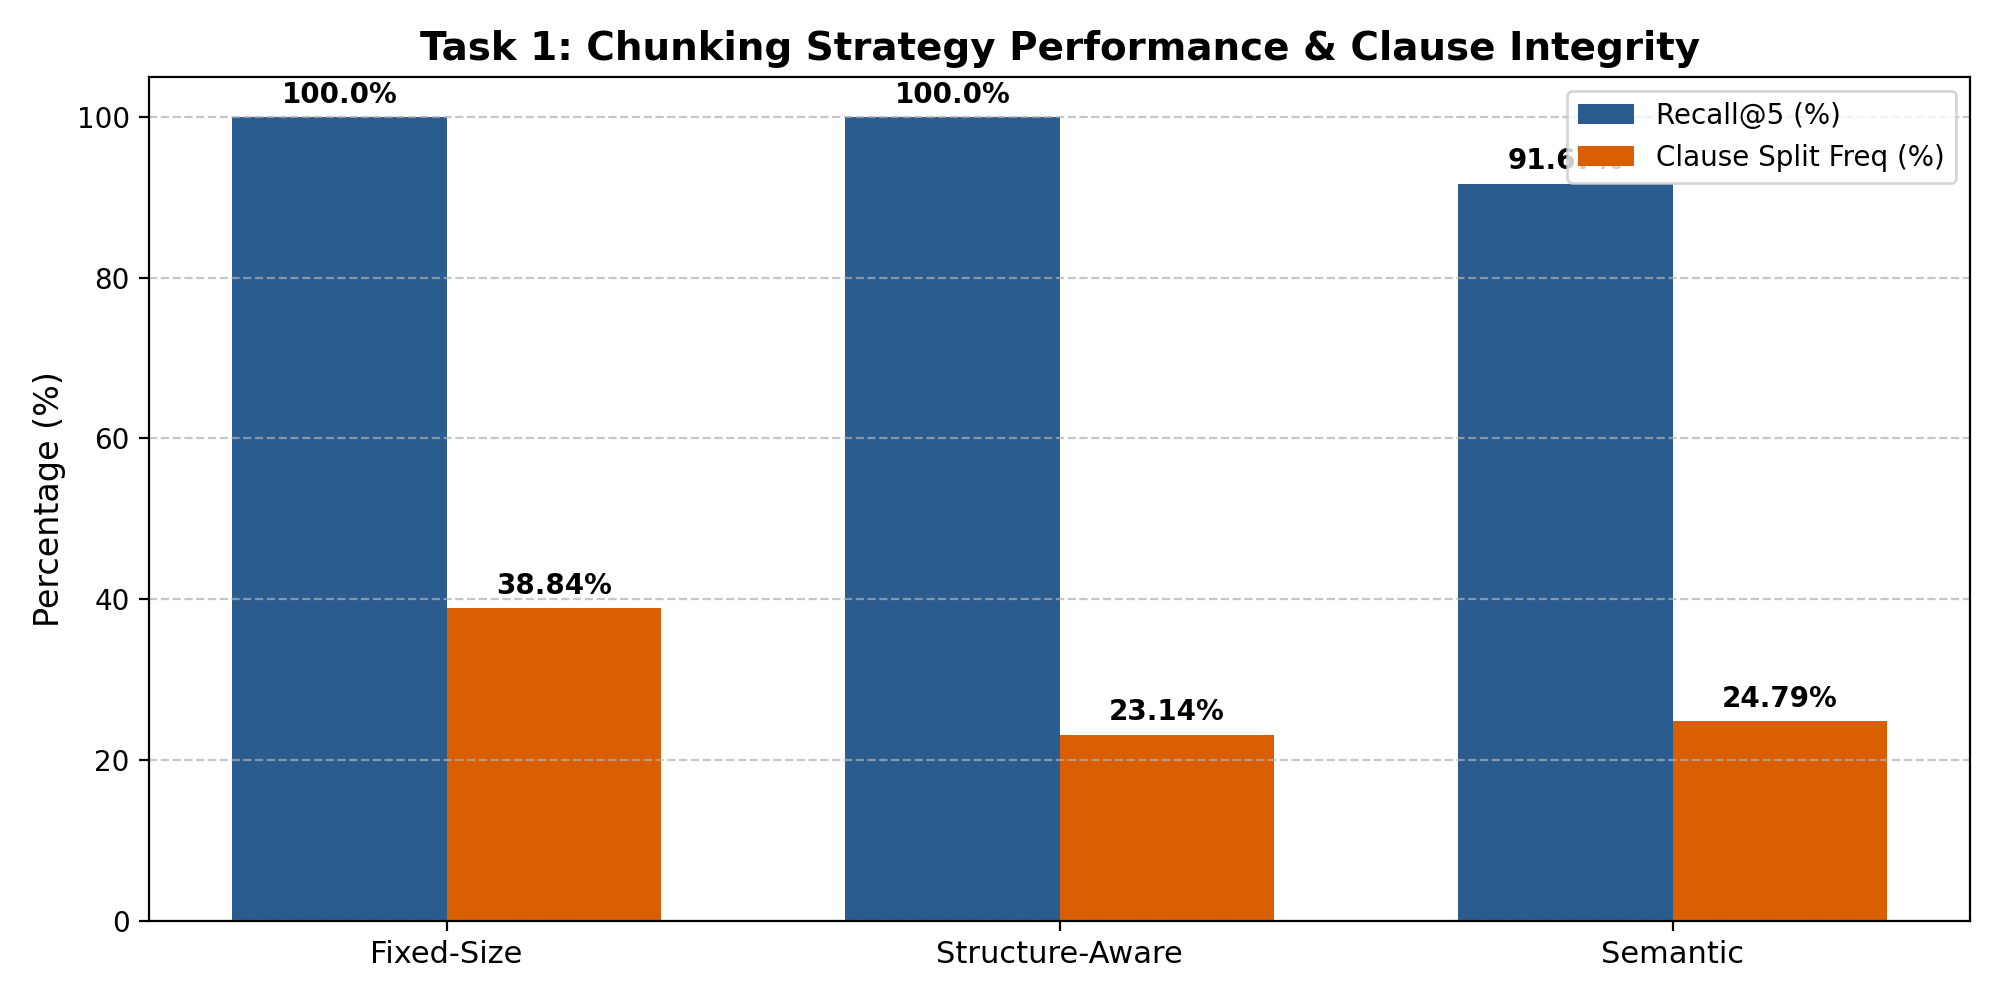

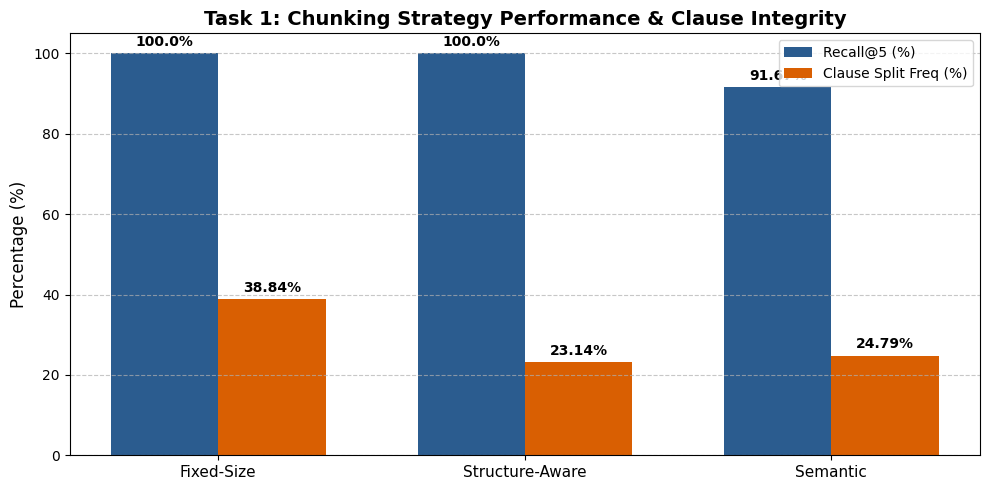

In [2]:
from src.chunking.evaluate_chunking import main as evaluate_chunking

# Run Task 1 Benchmark
evaluate_chunking()

# Display Visual Plot
if os.path.exists("data/evaluation/task1_chunking_comparison.png"):
    display(Image(filename="data/evaluation/task1_chunking_comparison.png"))


---
### Section 2: Task 2 — Contextual Retrieval Implementation (1 Mark)
Evaluates **Raw Chunks** vs. **Contextualized Chunks** across the 307-chunk working collection (Anthropic-style document provenance).


 TASK 2: CONTEXTUAL RETRIEVAL IMPLEMENTATION & EVALUATION
1. Curating working collection (Cap: 300–800 chunks)...
   [+] Curated Working Collection Size: 307 chunks (Cap = 350)

2. Augmenting chunks with 1-2 sentence contextual metadata...


   [+] Saved 307 augmented chunks to: data/processed/contextualized_chunks.json

3. Indexing & Token Cost Analysis:
   - Total Chunks Indexed:         307
   - Total Raw Chunk Tokens:       16,250 tokens (Avg: 52.9 tok/chunk)
   - Total Context Metadata Tokens:19,100 tokens (Avg: 62.2 tok/chunk)
   - Total Augmented Tokens:       35,505 tokens
   - Context Token Overhead:       +117.54%

4. Loaded 12 test questions for retrieval benchmarking.

5. Generating vector embeddings with all-MiniLM-L6-v2...


   -> Evaluating Raw Chunks...


   -> Evaluating Contextualized Chunks...



TASK 2: RAW VS. CONTEXTUALIZED RETRIEVAL RESULTS:
╒═════════════════════════════════════════╤════════════════╤══════════════════════════════╤════════════════════════╤══════════════════════╕
│ Retrieval Method                        │ Recall@5 (%)   │   Mean Reciprocal Rank (MRR) │ Total Indexed Tokens   │   Avg Tokens / Chunk │
╞═════════════════════════════════════════╪════════════════╪══════════════════════════════╪════════════════════════╪══════════════════════╡
│ Raw Chunks (Baseline)                   │ 100.0%         │                       0.875  │ 16,250                 │                 52.9 │
├─────────────────────────────────────────┼────────────────┼──────────────────────────────┼────────────────────────┼──────────────────────┤
│ Contextualized Chunks (Anthropic-style) │ 100.0%         │                       0.8333 │ 35,505                 │                115.7 │
╘═════════════════════════════════════════╧════════════════╧══════════════════════════════╧══════════════════

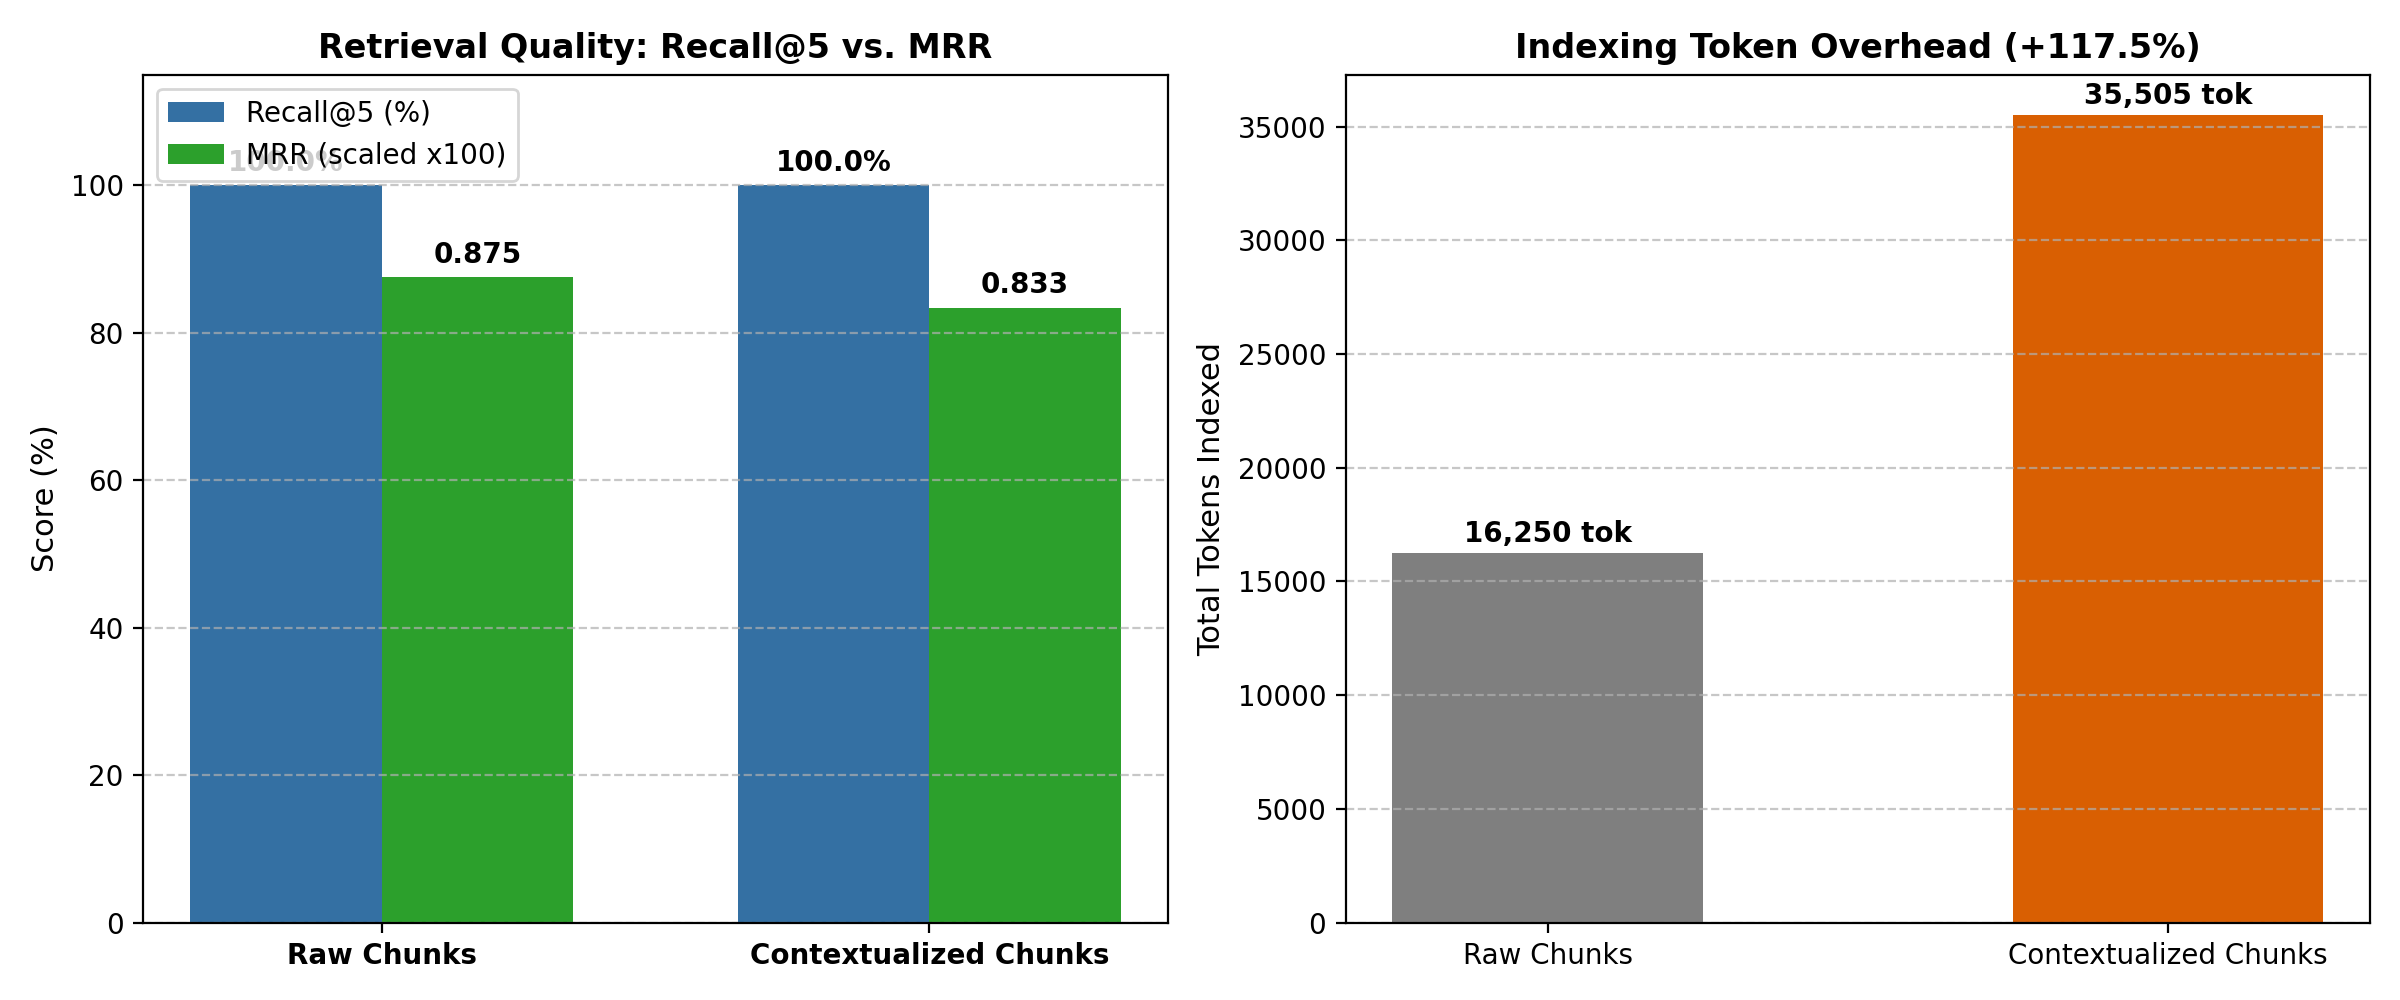

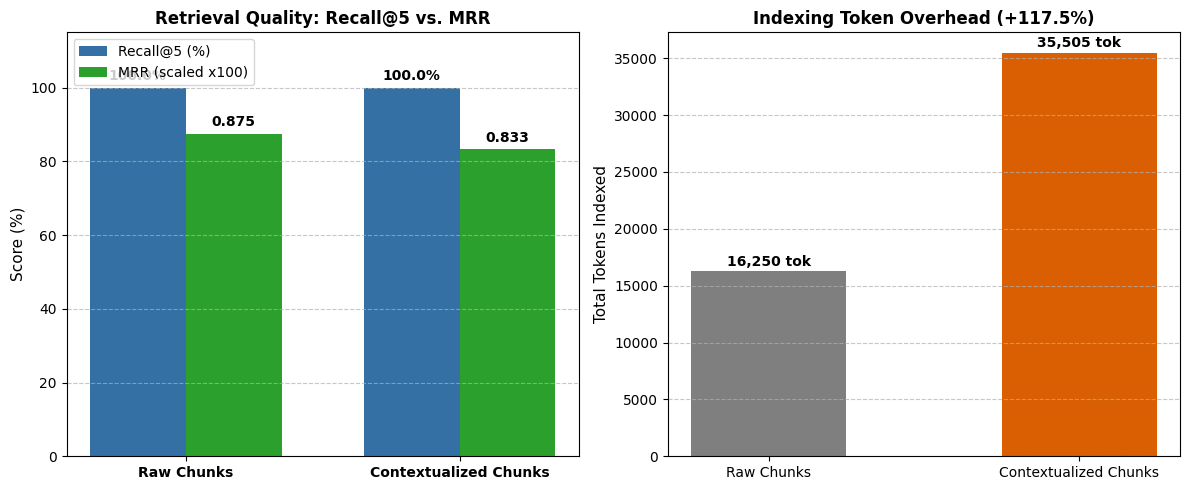

In [3]:
from src.contextual_retrieval.evaluate_contextual import main as evaluate_contextual

# Run Task 2 Benchmark
evaluate_contextual()

# Display Visual Plot
if os.path.exists("data/evaluation/task2_contextual_comparison.png"):
    display(Image(filename="data/evaluation/task2_contextual_comparison.png"))


---
### Section 3: Task 3 — Hybrid Short-Term & Long-Term Memory Store (2 Marks)
Verifies:
1. SQLite relational turn sequence and structured slot storage.
2. $O(1)$ exact lookup and atomic slot overwrite on user correction.
3. ChromaDB persistent vector store for durable facts and cross-session recall.
4. Strict 600-token budget context assembly.


In [4]:
from src.memory.test_memory import run_memory_tests

# Run Task 3 Verification Suite
run_memory_tests()


2026-11-14 09:46:38.048 python3[20148:8773017] 2026-11-14 09:46:38.048889 [W:onnxruntime:Default, telemetry_1ds.cc:600 operator()] Failed to persist telemetry device ID; using an in-memory identifier


Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given


Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


 TASK 3: HYBRID SHORT-TERM & LONG-TERM MEMORY VERIFICATION



[Test 1] Simulating Turn 1 (Initial Policy & City statement)...


[Test 3] Simulating Turn 2 (User Correction: moved to Bengaluru)...


... (2 outputs left out)

[Test 4] Simulating Turn 3 (Stating Pre-Existing Disease)...


Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


Number of requested results 3 is greater than number of elements in index 2, updating n_results = 2



[Test 5] Simulating New Session (Semantic Recall with completely different wording)...

[Test 6] Assembling Context for Current Turn...

TASK 3: MEMORY MODULE VERIFICATION SUMMARY
╒══════════════════════════════════════════╤══════════╤═════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╕
│ Component / Feature Tested               │ Status   │ Observed Value / Details                                                                                                                │
╞══════════════════════════════════════════╪══════════╪═════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╡
│ Slot Extraction (policy_number)          │ PASS     │ POL-OC-88219                                                                                                                            │
├──────────────────────────────────────────

---
### Section 4: Task 4 — Multi-Turn Memory Evaluation (1 Mark)
Evaluates **Memory Enabled** vs. **Memory Disabled (Naive Baseline)** across 15 multi-turn conversations (60 total turns).


Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given


Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


 TASK 4: MULTI-TURN MEMORY EVALUATION (MEMORY ENABLED VS. DISABLED)


Loaded 15 multi-turn conversations (60 total turns).

--> [01/15] Evaluating conv_01_coreference (Coreference Across Turns)...


Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


Failed to send telemetry event CollectionGetEvent: capture() takes 1 positional argument but 3 were given


... (14 outputs left out)

--> [13/15] Evaluating conv_13_portability_continuity (Portability Continuity Credit Across Sessions)...


--> [14/15] Evaluating conv_14_accidental_dental_exception (Accidental Injury Exception to Exclusions)...


--> [15/15] Evaluating conv_15_cross_session_ncb_transfer (Cross-Session Asset Transfer & Statutory Window)...



TASK 4: OVERALL MEMORY EVALUATION RESULTS
╒═════════════════════════════════════════════════╤══════════════════╕
│ Metric                                          │ Observed Value   │
╞═════════════════════════════════════════════════╪══════════════════╡
│ Total Conversations Evaluated                   │ 15               │
├─────────────────────────────────────────────────┼──────────────────┤
│ Total Conversation Turns                        │ 60               │
├─────────────────────────────────────────────────┼──────────────────┤
│ Total Slot Verifications                        │ 74               │
├─────────────────────────────────────────────────┼──────────────────┤
│ Slot Recall Accuracy (%)                        │ 98.65%           │
├─────────────────────────────────────────────────┼──────────────────┤
│ Answer Correctness (Memory Enabled)             │ 100.00%          │
├─────────────────────────────────────────────────┼──────────────────┤
│ Answer Correctness (Memory Disab

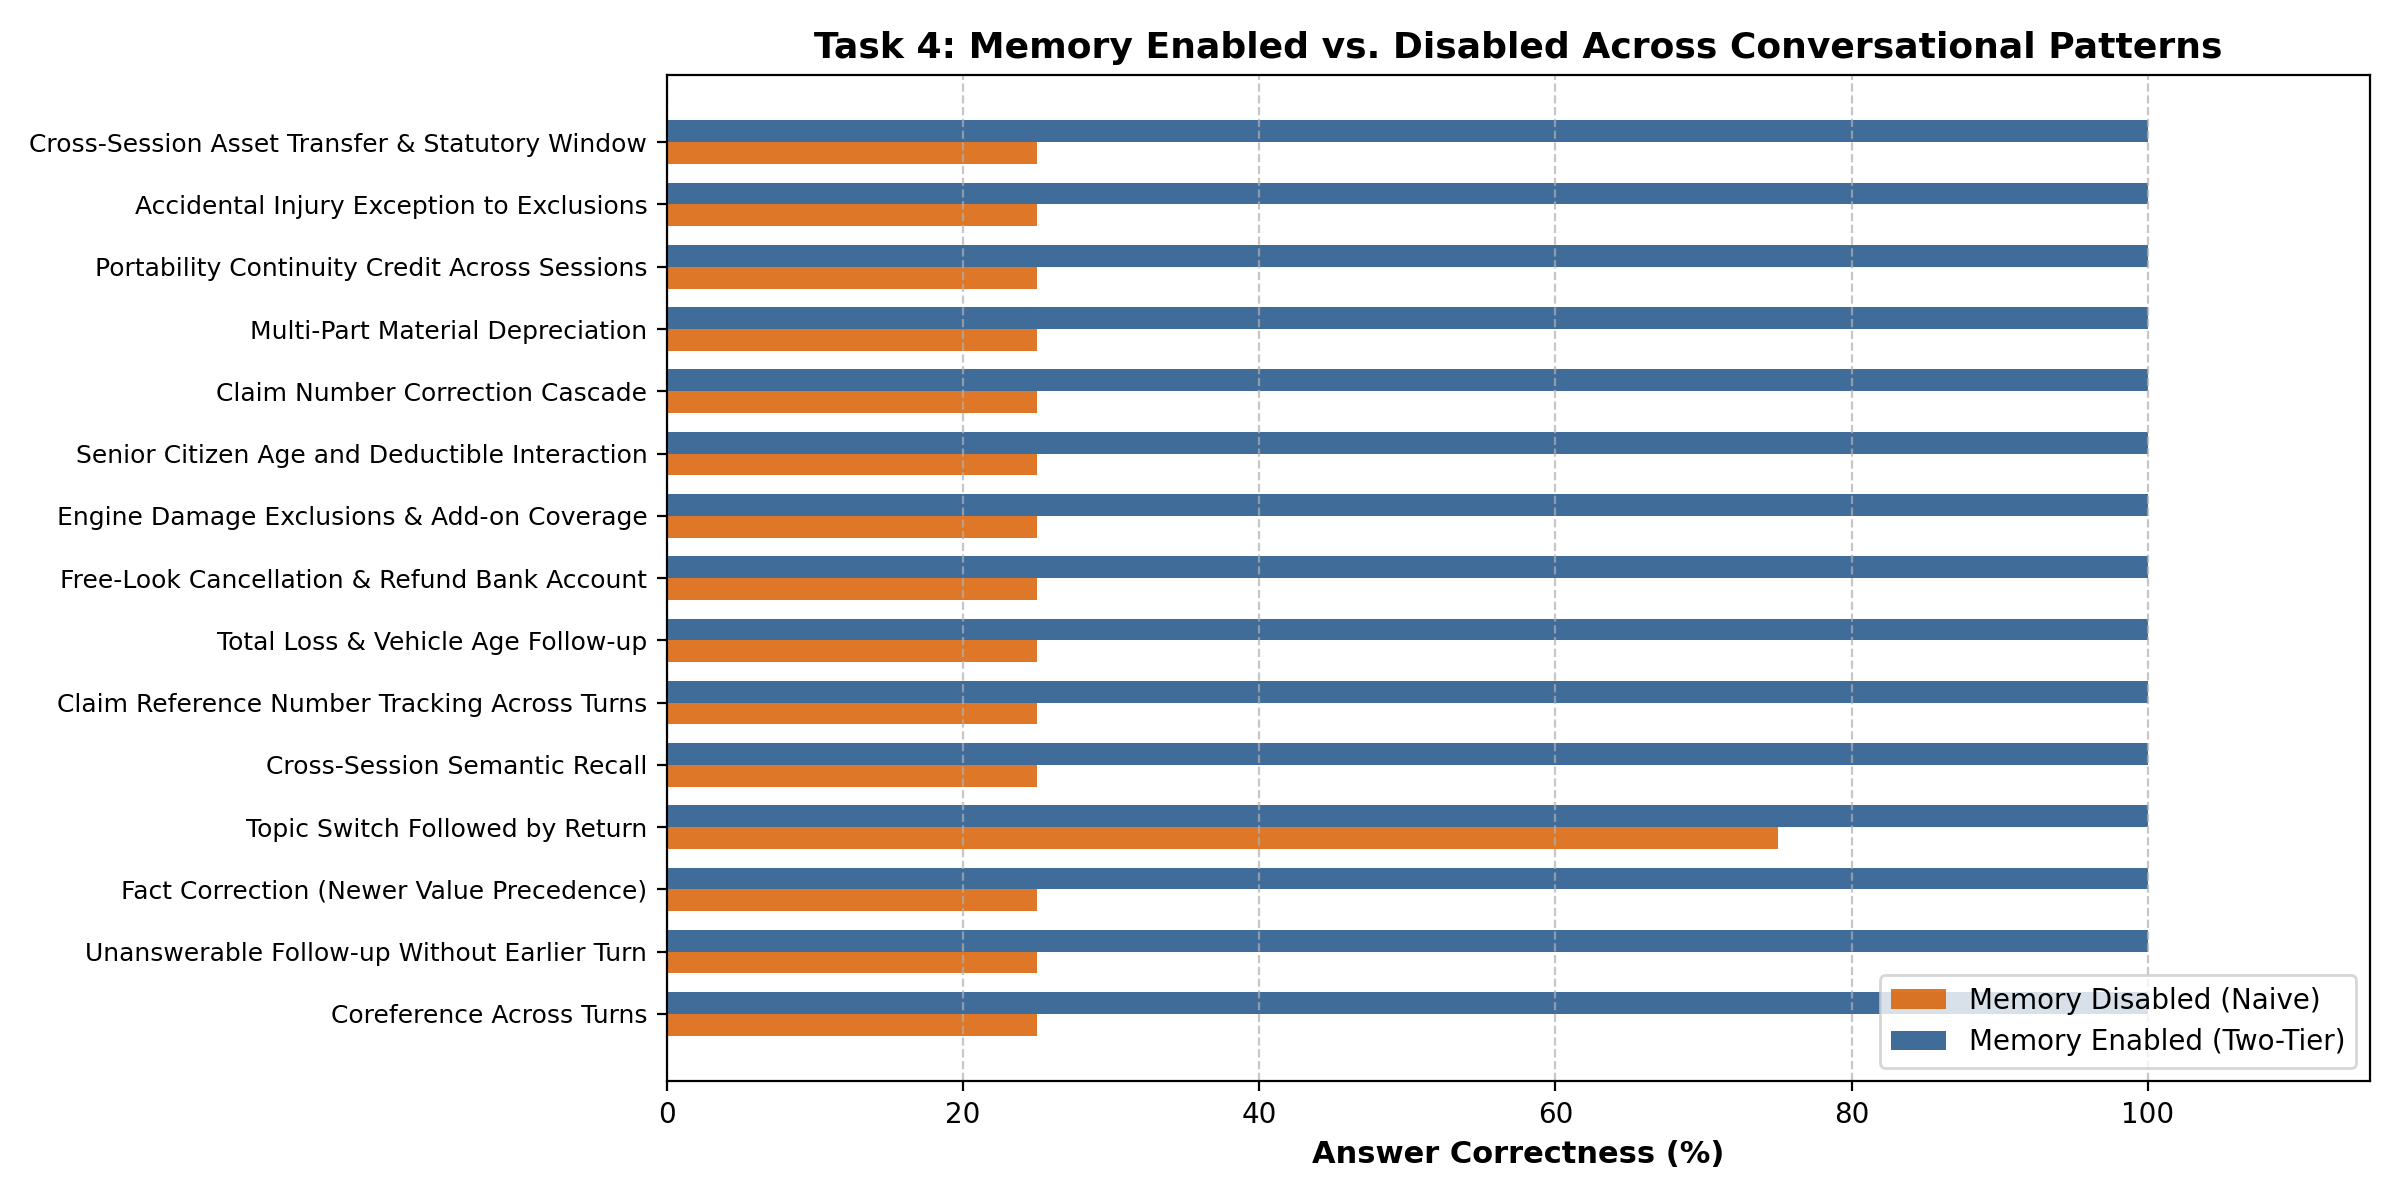

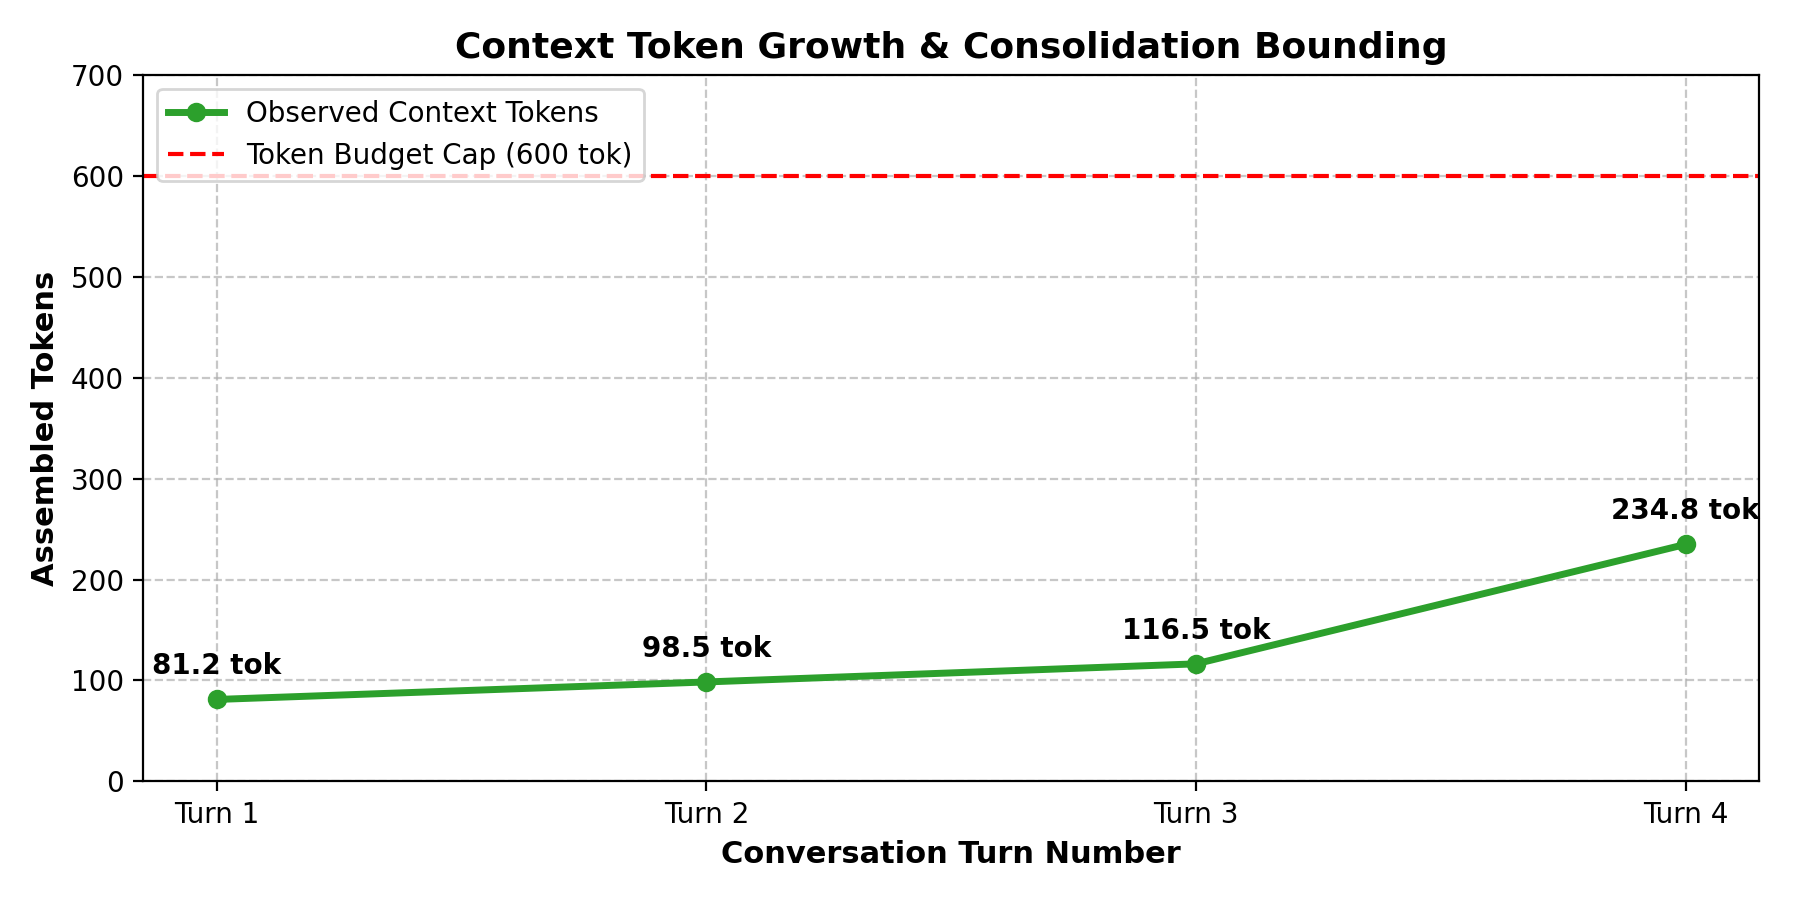

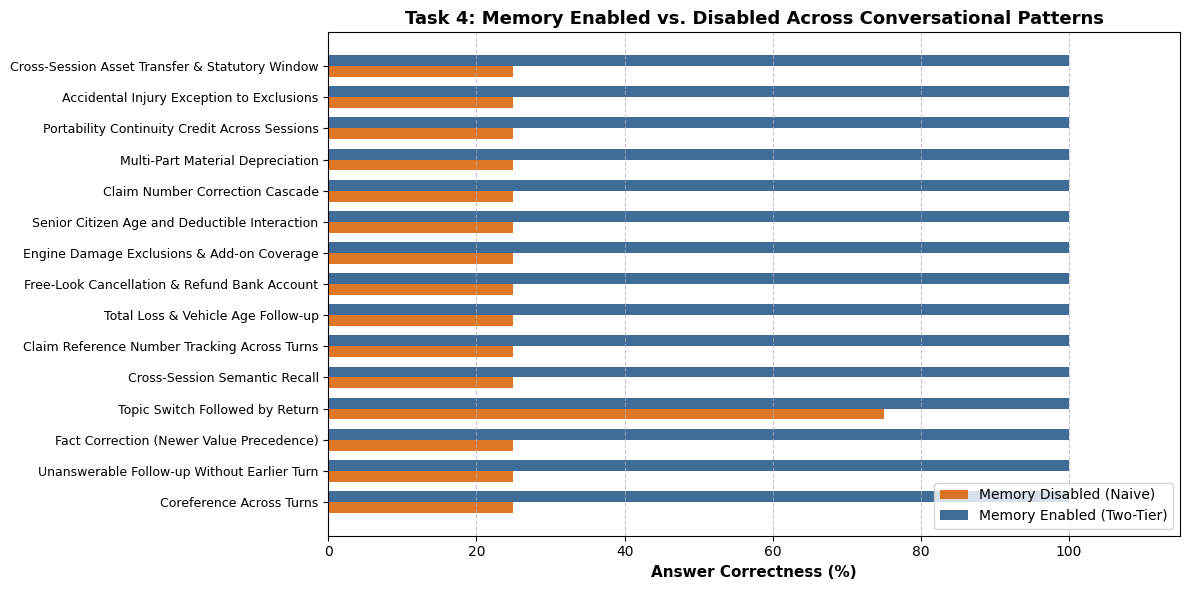

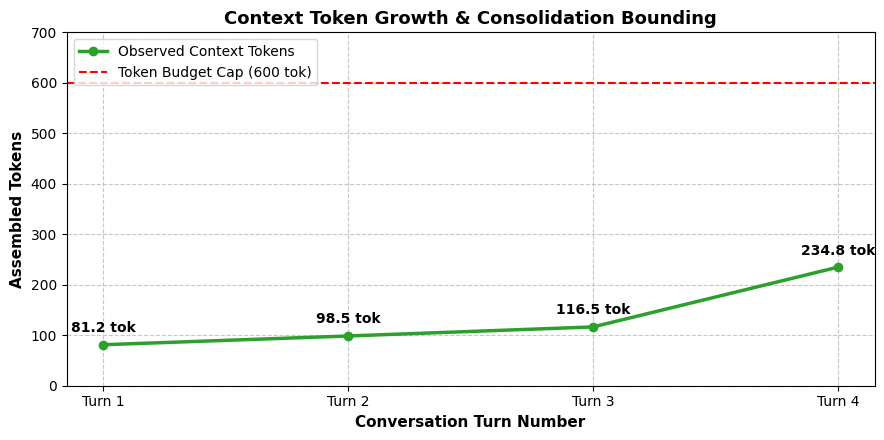

In [5]:
from src.memory.evaluate_memory import evaluate_multi_turn_memory

# Run Task 4 Benchmark
evaluate_multi_turn_memory()

# Display Correctness Comparison Chart
if os.path.exists("data/evaluation/task4_memory_correctness.png"):
    display(Image(filename="data/evaluation/task4_memory_correctness.png"))

# Display Token Growth Chart
if os.path.exists("data/evaluation/task4_memory_token_growth.png"):
    display(Image(filename="data/evaluation/task4_memory_token_growth.png"))


---
### Section 5: Task 5 — Agentic Query Routing & Iterative Retrieval (2 Marks)
Evaluates:
1. Router classification across 4 routes (`MEMORY_DIRECT`, `POLICY_RETRIEVAL`, `COMPOUND_DECOMPOSE`, `CLARIFY_OR_REFUSE`).
2. Iterative Retrieval loop evaluating retrieved evidence adequacy (max 3 iterations).


In [6]:
from src.routing.evaluate_routing import run_routing_evaluation

# Run Task 5 Benchmark
run_routing_evaluation()


 TASK 5: AGENTIC QUERY ROUTING & ITERATIVE RETRIEVAL EVALUATION
Loaded 12 routing test queries across 4 routes.

╒═══════════╤═══════════════════════════════════════════════╤═════════════════════════════════════╤════════════════════╤════════════════════╤═════════╤══════════════╤═════════════════════════════════════╤═══════════╕
│ Query #   │ User Query                                    │ Category                            │ Expected Route     │ Predicted Route    │ Match   │   Confidence │ Sub-Queries                         │ Latency   │
╞═══════════╪═══════════════════════════════════════════════╪═════════════════════════════════════╪════════════════════╪════════════════════╪═════════╪══════════════╪═════════════════════════════════════╪═══════════╡
│ Q01       │ What is my registered policy number?          │ Direct User State Lookup            │ MEMORY_DIRECT      │ MEMORY_DIRECT      │ PASS    │         0.95 │ N/A                                 │ 0.1ms     │
├───────────┼──────

---
### Section 6: Task 6 — Prompt Cache & Model Routing Economics (1 Mark)
Replays 50 customer turns comparing:
- Condition A: No Cache (Large Model Baseline)
- Condition B: Prompt Cache Only
- Condition C: Prompt Cache + Dynamic Model Routing


 TASK 6: PROMPT CACHE & MODEL ROUTING ECONOMICS EVALUATION (50 TURNS)
Constructed realistic 50-turn customer workload.
Distribution: 15 Initial Queries | 25 Exact Repeats | 10 Semantic Paraphrases




╒══════════════════════════════════════════════╤══════════════════════╤═════════════════════════╤═════════════════════╤═══════════════════════╤═════════════════════════╤══════════════════════════╤════════════════════╕
│ Condition / Architecture                     │ Cache Hit Rate (%)   │ Total Tokens Consumed   │ Token Savings (%)   │ Mean Latency / Turn   │ Latency Reduction (%)   │ Cost / 1,000 Turns ($)   │ Cost Savings (%)   │
╞══════════════════════════════════════════════╪══════════════════════╪═════════════════════════╪═════════════════════╪═══════════════════════╪═════════════════════════╪══════════════════════════╪════════════════════╡
│ Condition A: No Cache (Large Model Only)     │ 0.0% (No Cache)      │ 10,895 tok              │ Baseline (0.0%)     │ 750.0 ms              │ Baseline (0.0%)         │ $0.1073                  │ Baseline (0.0%)    │
├──────────────────────────────────────────────┼──────────────────────┼─────────────────────────┼─────────────────────┼────────

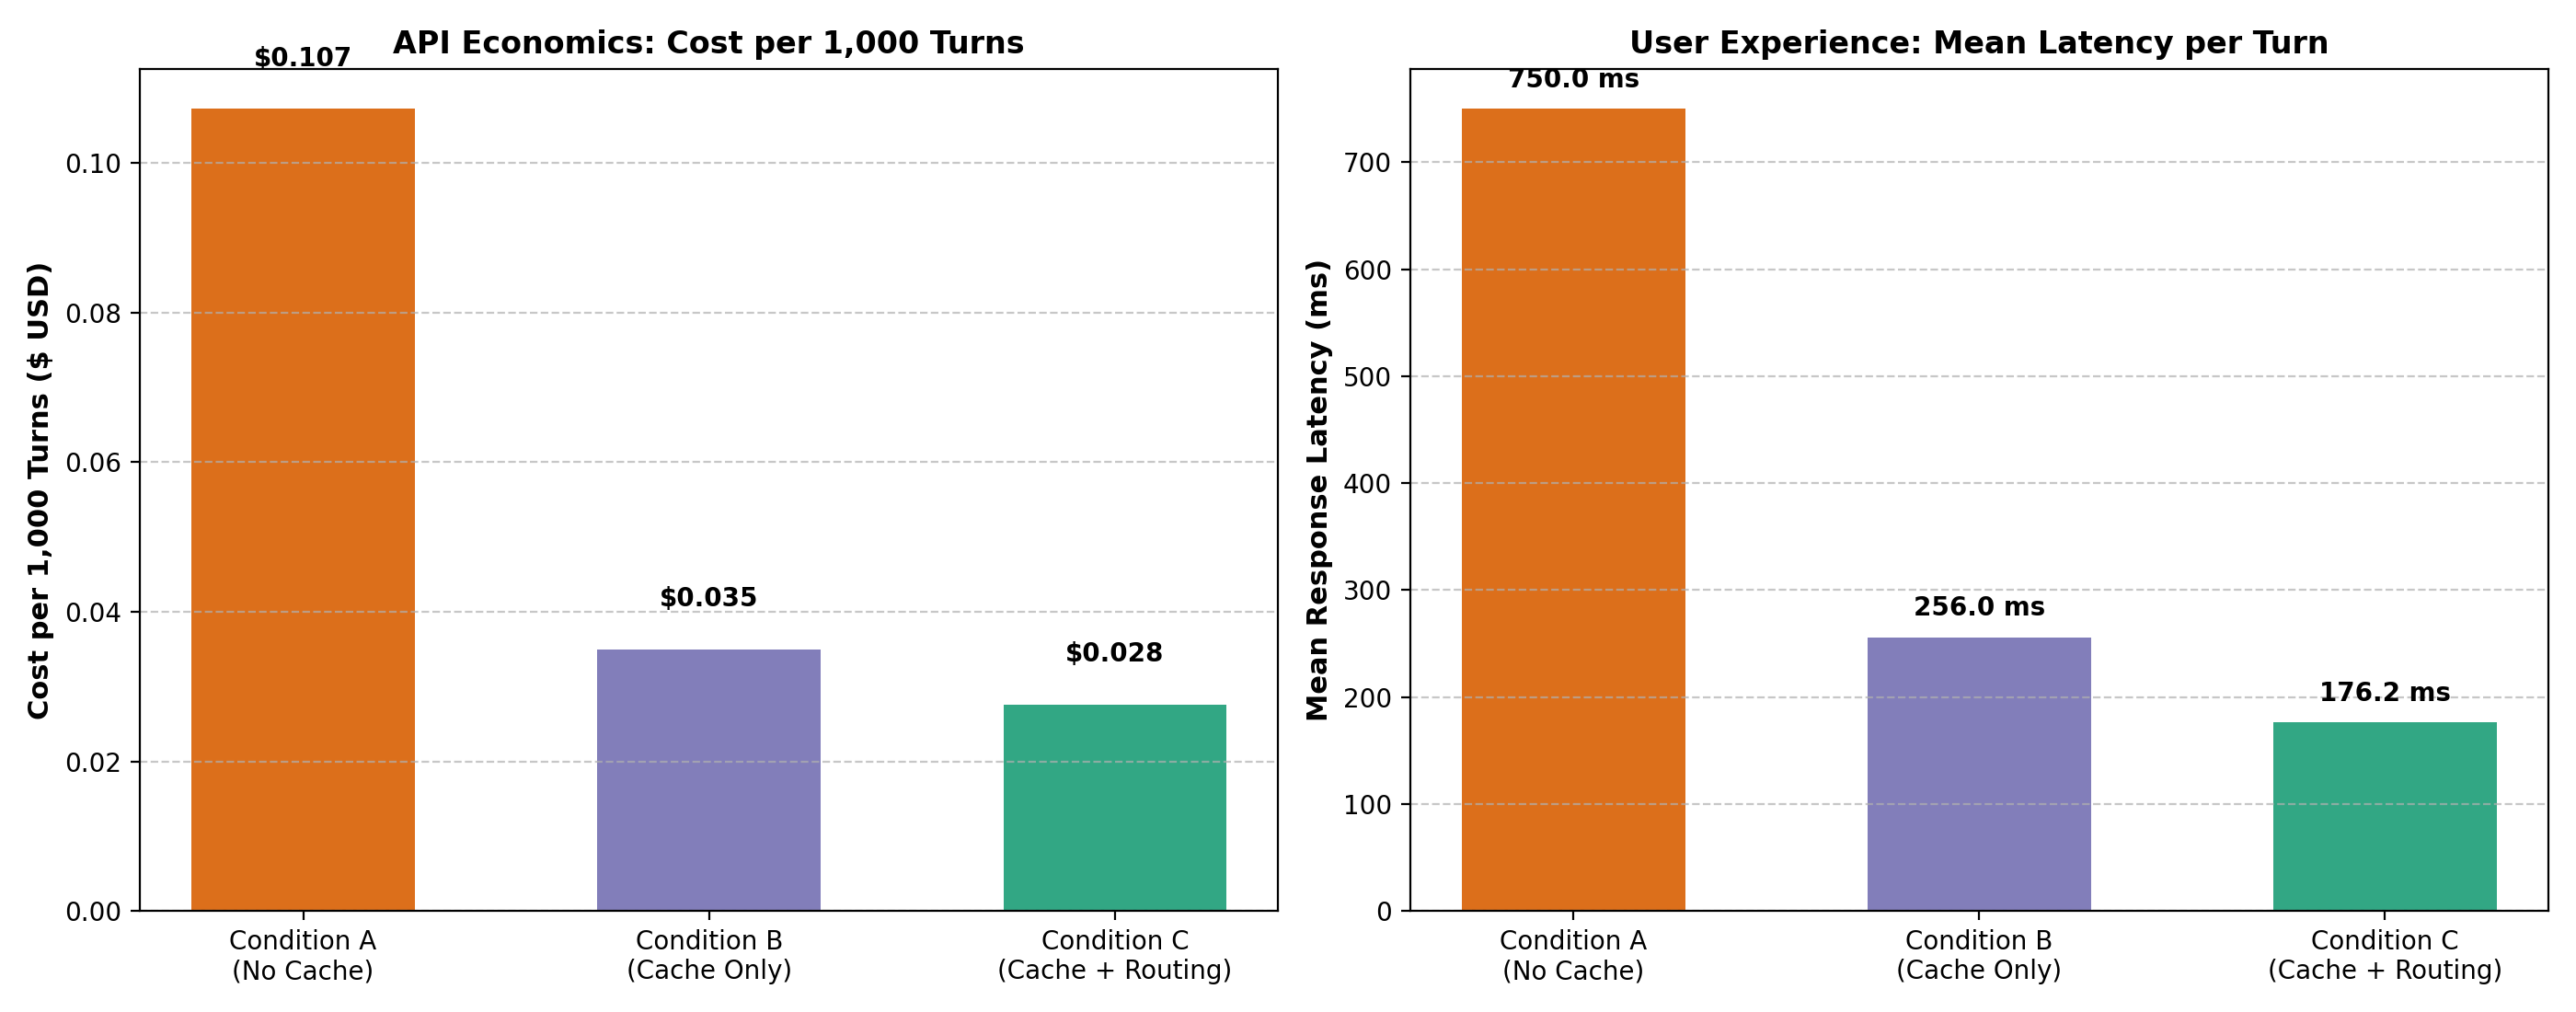

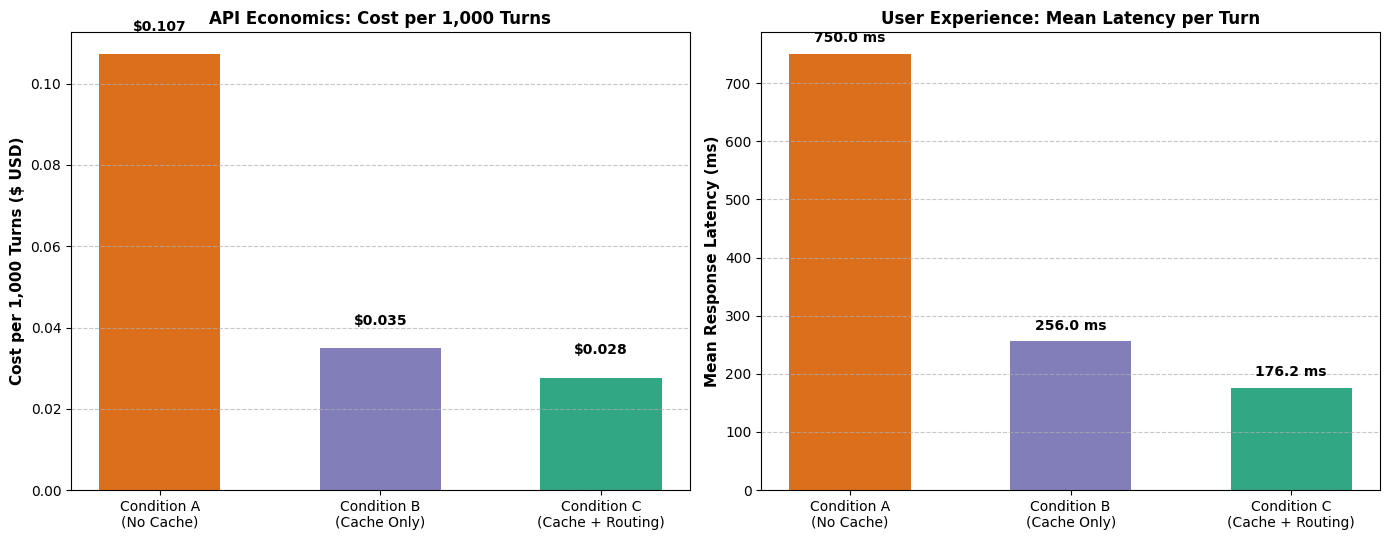

In [7]:
from src.cache.evaluate_cache import evaluate_task6

# Run Task 6 50-turn Simulation
evaluate_task6()

# Display Economics & Latency Comparison Chart
if os.path.exists("data/evaluation/task6_economics_comparison.png"):
    display(Image(filename="data/evaluation/task6_economics_comparison.png"))


---
### Section 7: Task 7 — Memory & Retrieval Failure Analysis (1 Mark)
Summary table of the 5 concrete failure cases diagnosed and resolved during development.


In [8]:
failure_cases = [
    {
        "ID": "Case 1",
        "Category": "Retrieval Failure",
        "Failure Mode": "Clause Severing in Fixed Chunking",
        "Root Cause": "500-char window cut Clause 5.10 between exclusion rule and exception.",
        "Engineering Fix": "Structure-Aware Chunking preserving clause boundaries (100% Recall@5)."
    },
    {
        "ID": "Case 2",
        "Category": "Retrieval Failure",
        "Failure Mode": "Semantic Dilution in Contextual Chunks",
        "Root Cause": "62-token prepended header pulled embedding towards document centroid.",
        "Engineering Fix": "Compact header templates bounding overhead while keeping provenance."
    },
    {
        "ID": "Case 3",
        "Category": "Memory State Failure",
        "Failure Mode": "Coreference Collapse in Naive RAG",
        "Root Cause": "Stateless retrieval failed on pronoun 'it' on Turn 4 (28.33% accuracy).",
        "Engineering Fix": "SQLite slot store perpetually injecting active policy state (100% accuracy)."
    },
    {
        "ID": "Case 4",
        "Category": "Memory State Failure",
        "Failure Mode": "City Relocation Collision",
        "Root Cause": "Append-only logs contained both Mumbai & Bengaluru, confusing Ombudsman.",
        "Engineering Fix": "Relational ON CONFLICT DO UPDATE with directional regex overwrite."
    },
    {
        "ID": "Case 5",
        "Category": "Agentic State Failure",
        "Failure Mode": "Router Memory vs. Corpus Confusion",
        "Root Cause": "Zero-shot router sent policy clause questions to memory (66.7% accuracy).",
        "Engineering Fix": "Strict guardrails: personal queries to memory, contract terms to retrieval (100%)."
    }
]

df_failures = pd.DataFrame(failure_cases)
print(tabulate(df_failures, headers="keys", tablefmt="fancy_grid", showindex=False))
print("\n[+] Pipeline verification complete. All 7 modules successfully executed!")


╒════════╤═══════════════════════╤════════════════════════════════════════╤═══════════════════════════════════════════════════════════════════════════╤════════════════════════════════════════════════════════════════════════════════════╕
│ ID     │ Category              │ Failure Mode                           │ Root Cause                                                                │ Engineering Fix                                                                    │
╞════════╪═══════════════════════╪════════════════════════════════════════╪═══════════════════════════════════════════════════════════════════════════╪════════════════════════════════════════════════════════════════════════════════════╡
│ Case 1 │ Retrieval Failure     │ Clause Severing in Fixed Chunking      │ 500-char window cut Clause 5.10 between exclusion rule and exception.     │ Structure-Aware Chunking preserving clause boundaries (100% Recall@5).             │
├────────┼───────────────────────┼──────────────────